Date : 17/11/2026

WISSAL MOUNIR / 23009068 / G3 / S7 FIN /
LIEN GITHUB : https://github.com/wissalmounir123/23009068-Wissal-Mounir-G3-FIN.git

# F3. Prévision de l'inflation : le chômage et le taux directeur aident-ils ?

**Algorithme principal : Ridge (n°2 du support)** · **Outils :** pandas, scikit-learn, matplotlib · **Graine :** `GRAINE = 42`

## 1. Sujet et problématique

**Intérêt du sujet.** Anticiper l'inflation à un an sert à des décideurs très différents : une banque centrale qui règle son taux directeur, une entreprise qui négocie des salaires ou des contrats indexés, un investisseur obligataire qui évalue le rendement réel de ses titres. La théorie économique suggère que le chômage (courbe de Phillips) et le taux directeur (réaction de la banque centrale) contiennent de l'information sur l'inflation future ; reste à savoir si elle s'ajoute à celle déjà contenue dans l'inflation passée.

**Problématique.** Sur les données mensuelles américaines, le **chômage** et le **taux directeur** réduisent-ils l'erreur de prévision de l'**inflation d'un an sur l'autre, 12 mois à l'avance**, par rapport à un modèle qui n'utilise que l'inflation passée ?

**Objectif mesurable.**

- *Métrique principale :* RMSE de test, en points de pourcentage d'inflation.
- *Référence simple :* la « dernière valeur » (l'inflation dans 12 mois sera égale à l'inflation d'aujourd'hui).
- *Jeu de test :* prévisions faites de janvier 2011 à août 2025 (cibles de 2011 à 2026), l'entraînement s'arrêtant à fin 2010 (`CUTOFF`).
- *Seuil de réussite :* RMSE du Ridge inférieur d'**au moins 10 %** à celui de la référence (valeur reprise de l'exemple de l'énoncé). Seconde condition : le Ridge qui utilise aussi le chômage et le taux doit faire mieux que le Ridge sur l'inflation seule.

**Nature du problème.** Apprentissage **supervisé**, plus précisément une **régression** (la variable à prédire est une valeur réelle) sur **séries temporelles mensuelles**. Deux conséquences : pas de découpage aléatoire (mélanger les mois permettrait au modèle de « voir le futur »), et une métrique d'erreur plutôt que l'exactitude : $\text{RMSE} = \sqrt{\dfrac{1}{n}\sum_i (y_i - \hat y_i)^2}$.

**Configuration.** Versions des bibliothèques et graine aléatoire :

In [1]:
# Importation des bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
import sklearn
import matplotlib

warnings.filterwarnings("ignore", category=FutureWarning)
GRAINE = 42                      # graine aléatoire fixée, comme dans le support
np.random.seed(GRAINE)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

def rmse(y_vrai, y_pred):
    # Racine de l'erreur quadratique moyenne
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)))

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)


Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | seaborn 0.13.2


## 2. Jeu de données

Les trois séries sont téléchargées directement depuis la base **FRED** (Réserve fédérale de Saint-Louis) par la cellule suivante.

In [2]:
# Chargement des trois séries depuis FRED
BASE_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="

def charger_serie(identifiant):
    # La première colonne du CSV est la date ; "." désigne une valeur manquante chez FRED
    s = pd.read_csv(BASE_URL + identifiant, index_col=0, parse_dates=True, na_values=".")
    return s[identifiant].astype(float)

brut = pd.concat({
    "CPI": charger_serie("CPIAUCSL"),
    "UNRATE": charger_serie("UNRATE"),
    "FEDFUNDS": charger_serie("FEDFUNDS"),
}, axis=1)
brut.index.name = "date"

print("Dimensions (avant alignement) :", brut.shape)
print("Période couverte :", brut.index.min().date(), "->", brut.index.max().date())
brut.head()

Dimensions (avant alignement) : (958, 3)
Période couverte : 1947-01-01 -> 2026-10-01


,CPI,UNRATE,FEDFUNDS
date,,,
1947-01-01,21.48,NaN,NaN
1947-02-01,21.62,NaN,NaN
1947-03-01,22.00,NaN,NaN
1947-04-01,22.00,NaN,NaN
1947-05-01,21.95,NaN,NaN


In [3]:
# Date d'extraction (les séries FRED sont mises à jour en continu et révisées)
print("Date d'extraction des données :", pd.Timestamp.today().date())

Date d'extraction des données : 2026-11-17


**Date d'extraction.** Affichée par la cellule ci-dessus : elle permet de reproduire les chiffres, car FRED met ses séries à jour et les révise.

**Sources exactes (URL).**

| Série | Page FRED | Organisme producteur |
|---|---|---|
| `CPIAUCSL` | https://fred.stlouisfed.org/series/CPIAUCSL | Bureau of Labor Statistics (États-Unis) |
| `UNRATE` | https://fred.stlouisfed.org/series/UNRATE | Bureau of Labor Statistics (États-Unis) |
| `FEDFUNDS` | https://fred.stlouisfed.org/series/FEDFUNDS | Réserve fédérale (Board of Governors) |

Téléchargement par le code : `https://fred.stlouisfed.org/graph/fredgraph.csv?id=<SÉRIE>`.

**Conditions d'utilisation.** Elles sont indiquées par FRED sur https://fred.stlouisfed.org/legal/ et sur la page de chaque série ; les données sont utilisées ici dans un cadre pédagogique, avec citation de la source.

**Taille et fréquence.** 958 lignes (un mois par ligne) et 3 variables brutes, de janvier 1947 à octobre 2026, fréquence **mensuelle**. Après alignement des trois séries et calcul de l'inflation, 854 mois de juillet 1955 à septembre 2026 ; 830 observations utilisables une fois les retards et la cible construits.

**Unité d'observation.** Un mois (une ligne = les valeurs des trois séries pour un mois donné).

**Dictionnaire des variables.**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| `CPI` (`CPIAUCSL`) | Indice des prix à la consommation, ensemble des ménages urbains, désaisonnalisé | numérique | indice (base 1982-1984 = 100) | brute, sert à calculer l'inflation | 0,2 (2 sur 958) |
| `UNRATE` | Taux de chômage | numérique | % de la population active | explicative | 1,4 (13 sur 958) |
| `FEDFUNDS` | Taux des fonds fédéraux effectif (taux directeur) | numérique | % | explicative | 9,4 (90 sur 958) |
| `infl` | Inflation annuelle $\pi_t = 100\,(CPI_t / CPI_{t-12} - 1)$ | numérique, créée | % | explicative (retardée) | 0 après alignement |
| `chomage`, `taux` | Copies de `UNRATE` et `FEDFUNDS` après alignement | numérique | % | explicatives | 0 après alignement |
| `infl_t-k`, `chomage_t-k`, `taux_t-k` | Valeur de la variable $k$ mois plus tôt, $k\in\{0,1,3,6,12\}$ (`shift(k)`) | numérique, créée | % | explicatives | 0 après construction |
| `infl_t+12` | **Cible** : inflation observée 12 mois plus tard, $y_t=\pi_{t+12}$ (`shift(-12)`) | numérique, créée | % | cible | 0 après construction |

Les manquants de `UNRATE` et `FEDFUNDS` sont en grande partie des mois **antérieurs au début de la série** (1948 et juillet 1954) ; ceux de `CPI` concernent le dernier mois et un mois isolé (voir section 3).

**Variable cible.** $y_t = \pi_{t+12}$, construite par décalage vers le futur ; les 12 derniers mois n'ont pas de cible et sont retirés.

**Adéquation.** Les séries sont longues (plus de 70 ans), mensuelles et publiques ; elles contiennent à la fois l'inflation à prévoir et les deux variables dont on veut tester l'apport. Elles permettent donc de répondre directement à la problématique.

**Limites.** (1) Les séries sont **révisées** après publication : on utilise les versions d'aujourd'hui, pas celles connues à l'époque (biais d'anticipation, section 8). (2) Plusieurs **régimes** successifs (années 1970-1980, après 2008, 2020-2022) rendent la relation entre variables instable. (3) Un seul pays. (4) Des mois consécutifs très dépendants : peu d'observations réellement indépendantes. (5) Un mois est absent à l'intérieur de la période alignée (section 3 et section 8.3).

## 3. Exploration

Les trois séries ne commencent pas à la même date : l'**alignement** par la date sera nécessaire. Le tableau ci-dessous donne le début, la fin et les manquants de chaque série, puis leurs statistiques descriptives.

In [4]:
# Début et fin de chaque série, valeurs manquantes
resume = pd.DataFrame({
    "première date": [brut[c].first_valid_index().date() for c in brut],
    "dernière date": [brut[c].last_valid_index().date() for c in brut],
    "valeurs manquantes": brut.isna().sum().values,
}, index=brut.columns)
print(resume)
print()
brut.describe().round(2)

         première date dernière date  valeurs manquantes
CPI         1947-01-01    2026-10-01                   1
UNRATE      1948-01-01    2026-10-01                  13
FEDFUNDS    1954-07-01    2026-10-01                  90



,CPI,UNRATE,FEDFUNDS
count,957.00,945.00,868.00
mean,126.03,5.65,4.59
std,91.25,1.70,3.52
min,21.48,2.50,0.05
25%,32.90,4.30,1.94
50%,110.40,5.40,4.24
75%,202.90,6.70,6.10
max,337.48,14.80,19.10


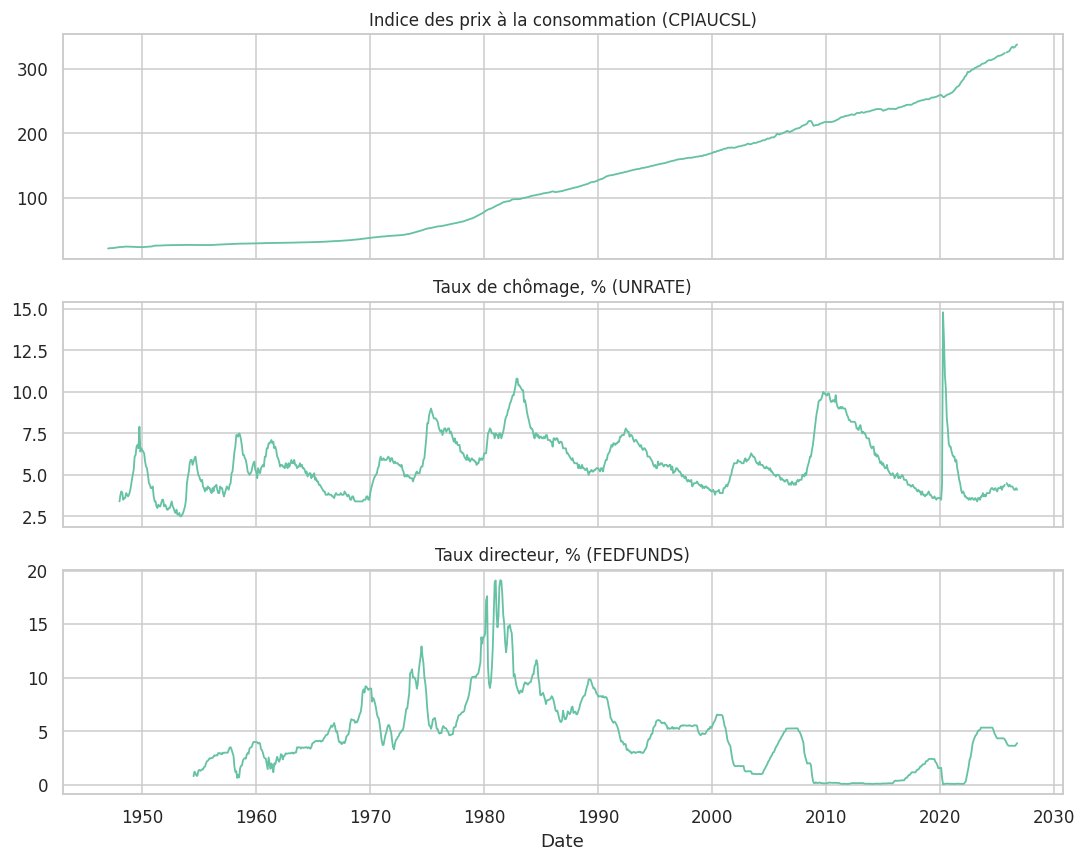

In [5]:
# Aperçu des trois séries brutes
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
titres = ["Indice des prix à la consommation (CPIAUCSL)", "Taux de chômage, % (UNRATE)", "Taux directeur, % (FEDFUNDS)"]
for ax, col, titre in zip(axes, brut.columns, titres):
    ax.plot(brut.index, brut[col], lw=1.2)
    ax.set_title(titre, fontsize=11)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

**Interprétation du graphique 1 (séries brutes).** L'indice des prix augmente de façon continue sur toute la période, avec une pente plus forte dans les années 1970 et au début des années 1980. Le chômage monte brutalement lors des récessions, avec un pic à 14,8 % en 2020, alors que le taux directeur atteint plus de 19 % au début des années 1980, puis tombe près de zéro après 2008 et en 2020 avant de remonter depuis 2022. Les trois séries ne se comportent donc pas de la même façon selon les époques : la relation entre elles change de régime, ce qui rend la prévision difficile. Les statistiques descriptives vont dans le même sens : le taux directeur va de 0,05 % à 19,1 % et le chômage de 2,5 % à 14,8 %, sur de longues périodes très différentes.

In [6]:
# Qualité des données : doublons de dates, manquants, trous à l'intérieur de la période, valeurs atypiques
brut_complet = brut.copy()          # copie des séries brutes, conservée pour les vérifications

print("Dates en double :", int(brut_complet.index.duplicated().sum()))
for c in brut_complet:
    debut, fin = brut_complet[c].first_valid_index(), brut_complet[c].last_valid_index()
    interne = brut_complet.loc[debut:fin, c]
    trous = [d.strftime("%Y-%m") for d in interne[interne.isna()].index]
    print(f"{c:9s} : {brut_complet[c].isna().mean() * 100:4.1f} % de manquants ; trous à l'intérieur de la période : {trous}")

# Valeurs atypiques (règle de l'écart interquartile) sur les trois grandeurs utilisées
expl = brut_complet.dropna().copy()
expl["infl"] = (expl["CPI"] / expl["CPI"].shift(12) - 1) * 100
expl = expl[["infl", "UNRATE", "FEDFUNDS"]].dropna()
print()
for c in expl:
    q1, q3 = expl[c].quantile([0.25, 0.75])
    seuil_bas, seuil_haut = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    atyp = expl[c][(expl[c] < seuil_bas) | (expl[c] > seuil_haut)]
    par_decennie = atyp.groupby(atyp.index.year // 10 * 10).size().to_dict()
    print(f"{c:9s} : {len(atyp):3d} mois atypiques (hors [{seuil_bas:.1f} ; {seuil_haut:.1f}]), par décennie : {par_decennie}")

Dates en double : 0
CPI       :  0.1 % de manquants ; trous à l'intérieur de la période : ['2025-10']
UNRATE    :  1.4 % de manquants ; trous à l'intérieur de la période : ['2025-10']
FEDFUNDS  :  9.4 % de manquants ; trous à l'intérieur de la période : []

infl      :  65 mois atypiques (hors [-2.2 ; 8.3]), par décennie : {1970: 37, 1980: 24, 2020: 4}
UNRATE    :   5 mois atypiques (hors [0.7 ; 10.7]), par décennie : {1980: 2, 2020: 3}
FEDFUNDS  :  30 mois atypiques (hors [-4.2 ; 12.3]), par décennie : {1970: 4, 1980: 26}


**Qualité des données : problèmes, détection, décisions.**

| Problème | Méthode de détection | Décision | Justification |
|---|---|---|---|
| Valeurs manquantes en début de série | première date valide de chaque série | on garde seulement les mois où les trois séries existent (alignement, section 4) | `FEDFUNDS` n'existe qu'à partir de 1954 : avant, la comparaison des variables est impossible ; on n'invente aucune valeur |
| Dernier mois incomplet, mois isolé absent à l'intérieur de la période | cellule ci-dessus (trous à l'intérieur de la période) | ligne supprimée lors de l'alignement (`dropna`) ; effet vérifié en section 8.3 | pas d'imputation, qui fabriquerait de l'information ; les décalages comptent des lignes, pas des mois, d'où la vérification |
| Dates en double | `index.duplicated()` | à traiter si le compte affiché n'est pas nul | une série FRED mensuelle a une ligne par date |
| Valeurs atypiques | règle de l'écart interquartile, comptage par décennie | **conservées** | ce sont des épisodes réels (inflation des années 1970, pic de chômage de 2020, taux directeur de 19 % en 1981) : ils portent précisément le risque que l'on veut prévoir |

**Graphique 2 : distribution des variables.**

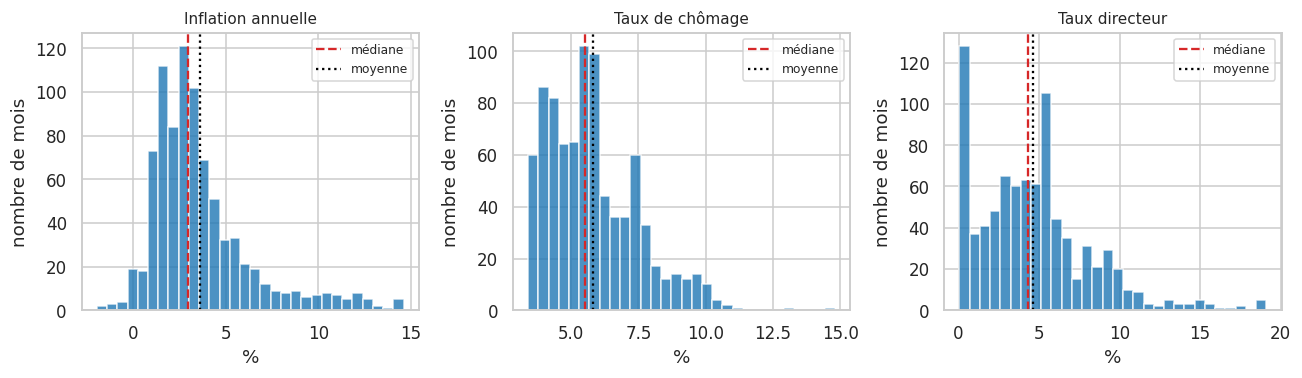

In [7]:
# Graphique 2 : distribution de l'inflation, du chômage et du taux directeur (mois alignés)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, titre, unite in zip(axes, ["infl", "UNRATE", "FEDFUNDS"],
                                 ["Inflation annuelle", "Taux de chômage", "Taux directeur"], ["%", "%", "%"]):
    ax.hist(expl[col], bins=30, color="tab:blue", alpha=0.8)
    ax.axvline(expl[col].median(), color="tab:red", ls="--", label="médiane")
    ax.axvline(expl[col].mean(), color="black", ls=":", label="moyenne")
    ax.set_title(titre, fontsize=10)
    ax.set_xlabel(unite)
    ax.set_ylabel("nombre de mois")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interprétation.** Les histogrammes montrent la forme de chaque distribution sur l'ensemble de la période. Quand la moyenne (pointillés noirs) s'écarte de la médiane (tirets rouges), la distribution est asymétrique : c'est le signe de queues longues, liées aux épisodes de forte inflation et de taux très élevés des années 1970-1980 et aux pics de chômage des récessions. Conséquence pour la modélisation : les erreurs de prévision seront dominées par quelques épisodes extrêmes, ce qui justifie le choix du RMSE (qui pénalise fortement les grosses erreurs) comme métrique principale, accompagné de la MAE, moins sensible à ces épisodes.

**Graphique 3 : corrélations entre variables (période alignée).**

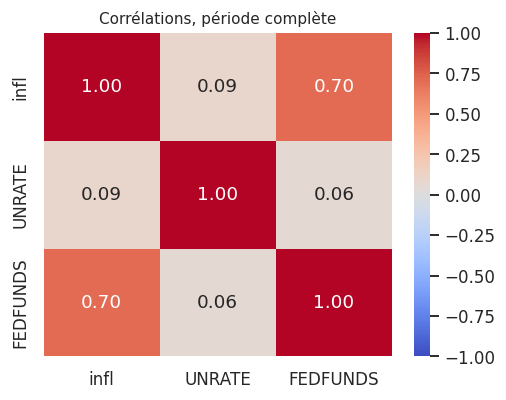

In [8]:
# Graphique 3 : matrice de corrélation (contemporaine) entre les trois variables
fig, ax = plt.subplots(figsize=(4.8, 3.8))
sns.heatmap(expl.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations, période complète", fontsize=10)
plt.tight_layout()
plt.show()

**Interprétation.** Cette matrice résume la liaison linéaire entre variables **sur toute la période**. Elle doit être lue avec prudence : une corrélation moyenne cache des changements de régime (le lien entre taux directeur et inflation n'est pas le même dans les années 1970, après 2008 ou en 2022), et elle ne dit rien de la causalité, puisque la banque centrale **réagit** à l'inflation. Elle indique en revanche si les variables explicatives sont fortement liées entre elles, ce qui est la situation où un modèle régularisé comme le Ridge est pertinent.

## 4. Préparation

Étapes, dans l'ordre :

1. **Aligner les dates** : on ne garde que les mois où les trois séries existent.
2. **Calculer l'inflation annuelle** : variation en % de l'indice par rapport au même mois un an plus tôt, $\pi_t = 100\,\left(\dfrac{CPI_t}{CPI_{t-12}} - 1\right)$. Cette transformation rend la série stationnaire en moyenne, ce que l'indice brut n'est pas.
3. **Construire des retards** (*lags*) : le modèle ne connaît que le présent et le passé. Pour chaque variable, on utilise la valeur à $t$, $t-1$, $t-3$, $t-6$ et $t-12$.
4. **Définir la cible** : $y_t = \pi_{t+12}$, l'inflation observée 12 mois plus tard. La dernière année de données n'a donc pas de cible et disparaît.
5. **Découper** dans l'ordre du temps (voir plus bas), puis standardiser **dans un `Pipeline`**.

**Prévention des fuites de données.**

- Les retards utilisent `shift(k)` avec $k$ positif ; la cible utilise `shift(-12)` puis on retire les lignes incomplètes. Les premières lignes affichées plus bas (date, variables, cible) permettent de vérifier l'alignement.
- Découpage chronologique, sans mélange aléatoire, avec un **trou de 12 mois** entre l'entraînement et le test, puisque la cible porte sur un horizon de 12 mois.
- La standardisation est apprise sur chaque pli d'entraînement seulement, grâce au `Pipeline`. Elle est **nécessaire pour le Ridge** (la pénalité dépend de l'échelle des variables) et **inutile pour le gradient boosting** (les arbres ne dépendent pas de l'échelle).
- Aucune variable ne contient la cible, même indirectement.

**Point d'attention : le calendrier.** Les décalages (`shift`) comptent des **lignes**, pas des mois. Si un mois est absent après le `dropna`, les observations qui suivent ce trou ont un retard ou une cible décalés d'un mois de plus que prévu. Le nombre de lignes obtenu (854) est inférieur d'une unité au nombre de mois entre juillet 1955 et septembre 2026 (855) : un mois manque donc bel et bien à l'intérieur de la période. L'effet est limité aux observations proches de ce trou ; il est mesuré en section 8.3 par un recalcul sur un calendrier mensuel complet.

Observations après alignement et calcul de l'inflation : 855
Période : 1955-07-01 -> 2026-10-01


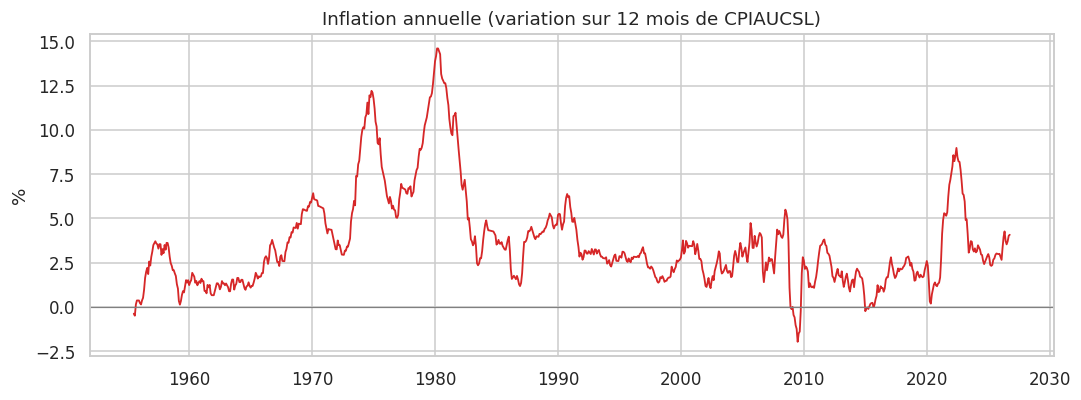

In [9]:
# 1) Alignement : on garde les mois où les trois séries sont disponibles
brut = brut.dropna()

# 2) Inflation annuelle (variation en % sur 12 mois)
df = pd.DataFrame(index=brut.index)
df["infl"] = (brut["CPI"] / brut["CPI"].shift(12) - 1) * 100
df["chomage"] = brut["UNRATE"]
df["taux"] = brut["FEDFUNDS"]
df = df.dropna()

print("Observations après alignement et calcul de l'inflation :", len(df))
print("Période :", df.index.min().date(), "->", df.index.max().date())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(df.index, df["infl"], lw=1.2, color="tab:red")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Inflation annuelle (variation sur 12 mois de CPIAUCSL)")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

In [10]:
# 3) Variables retardées et 4) cible à 12 mois
HORIZON = 12
RETARDS = [0, 1, 3, 6, 12]          # 0 = valeur courante
VARIABLES = ["infl", "chomage", "taux"]

def etiquette(k):
    return "t" if k == 0 else f"t-{k}"

def construire_X(variables, retards):
    cols = {f"{v}_{etiquette(k)}": df[v].shift(k) for v in variables for k in retards}
    return pd.DataFrame(cols)

X_tout = construire_X(VARIABLES, RETARDS)
y_tout = df["infl"].shift(-HORIZON).rename("infl_t+12")

donnees = pd.concat([X_tout, y_tout], axis=1).dropna()
print("Observations utilisables :", len(donnees))
print("Origines de prévision :", donnees.index.min().date(), "->", donnees.index.max().date())

# Jeux de variables comparés
cols_complet = list(X_tout.columns)
cols_infl = [c for c in cols_complet if c.startswith("infl_")]
groupes = {
    "Inflation": [c for c in cols_complet if c.startswith("infl_")],
    "Chômage": [c for c in cols_complet if c.startswith("chomage_")],
    "Taux directeur": [c for c in cols_complet if c.startswith("taux_")],
}
donnees.head()

Observations utilisables : 831
Origines de prévision : 1956-07-01 -> 2025-09-01


,infl_t,infl_t-1,infl_t-3,infl_t-6,infl_t-12,chomage_t,chomage_t-1,chomage_t-3,chomage_t-6,chomage_t-12,taux_t,taux_t-1,taux_t-3,taux_t-6,taux_t-12,infl_t+12
date,,,,,,,,,,,,,,,,
1956-07-01,1.980568,1.647323,0.522583,0.224131,-0.372301,4.4,4.3,4.0,4.0,4.0,2.75,2.71,2.62,2.45,1.68,3.297911
1956-08-01,2.208084,1.980568,0.971236,0.149142,-0.484171,4.1,4.4,4.3,3.9,4.2,2.73,2.75,2.75,2.50,1.96,3.551813
1956-09-01,1.862197,2.208084,1.647323,0.373274,0.149198,3.9,4.1,4.3,4.2,4.1,2.95,2.73,2.71,2.50,2.18,3.546618
1956-10-01,2.572707,1.862197,1.980568,0.522583,0.374251,3.9,3.9,4.4,4.0,4.3,2.96,2.95,2.75,2.62,2.24,2.944384
1956-11-01,2.343750,2.572707,2.208084,0.971236,0.373413,4.3,3.9,4.1,4.3,4.2,2.88,2.96,2.73,2.75,2.35,3.271538


**Lecture.** Les premières lignes montrent l'alignement attendu : sur chaque ligne, les colonnes `_t`, `_t-1`, … ne contiennent que des valeurs passées ou présentes, et `infl_t+12` l'inflation observée un an plus tard. Les observations sont construites à partir du mois de juillet 1956 (les 12 premiers mois servent aux retards).

**Découpage temporel.** On choisit une date de coupure `CUTOFF`. Le modèle est entraîné avec ce qui était **connu à cette date** : une observation entre dans l'entraînement seulement si sa **cible** est datée au plus tard de `CUTOFF` (trou de 12 mois). Le test porte sur les origines postérieures à `CUTOFF`. Pour la validation croisée dans l'entraînement, on utilise `TimeSeriesSplit` avec le même trou (`gap=12`) : chaque pli entraîne sur le passé et valide sur la période qui suit.

Avec `CUTOFF` = décembre 2010 : entraînement sur 642 observations (origines de juillet 1956 à décembre 2009), test sur 176 observations (origines de janvier 2011 à août 2025, cibles de 2011 à 2026), 5 plis de validation croisée.

In [11]:
# Découpage temporel, avec trou de 12 mois pour éviter la fuite de cible
CUTOFF = pd.Timestamp("2010-12-01")     # à modifier pour tester d'autres coupures

dates = donnees.index
date_cible = dates + pd.DateOffset(months=HORIZON)

masque_train = date_cible <= CUTOFF
masque_test = dates > CUTOFF

X_train, y_train = donnees.loc[masque_train, cols_complet], donnees.loc[masque_train, "infl_t+12"]
X_test, y_test = donnees.loc[masque_test, cols_complet], donnees.loc[masque_test, "infl_t+12"]

print(f"Entraînement : {len(X_train)} obs., origines {X_train.index.min().date()} -> {X_train.index.max().date()}")
print(f"Test         : {len(X_test)} obs., origines {X_test.index.min().date()} -> {X_test.index.max().date()}")

tscv = TimeSeriesSplit(n_splits=5, gap=HORIZON)
for i, (a, b) in enumerate(tscv.split(X_train), 1):
    print(f"Pli {i} : entraînement jusqu'à {X_train.index[a[-1]].date()} | validation {X_train.index[b[0]].date()} -> {X_train.index[b[-1]].date()}")

Entraînement : 642 obs., origines 1956-07-01 -> 2009-12-01
Test         : 177 obs., origines 2011-01-01 -> 2025-09-01
Pli 1 : entraînement jusqu'à 1964-05-01 | validation 1965-06-01 -> 1974-04-01
Pli 2 : entraînement jusqu'à 1973-04-01 | validation 1974-05-01 -> 1983-03-01
Pli 3 : entraînement jusqu'à 1982-03-01 | validation 1983-04-01 -> 1992-02-01
Pli 4 : entraînement jusqu'à 1991-02-01 | validation 1992-03-01 -> 2001-01-01
Pli 5 : entraînement jusqu'à 2000-01-01 | validation 2001-02-01 -> 2009-12-01


## 5. Algorithme : régression Ridge

**Choix et justification.** La tâche est une régression sur séries mensuelles, avec des variables explicatives (les retards) **très corrélées entre elles** et environ 640 observations d'entraînement. Le point d'attention du sujet est que les séries sont **révisées après publication** : un modèle simple, stable et peu flexible est plus facile à défendre qu'un modèle qui pourrait s'ajuster aux particularités des valeurs « nettoyées ». Le Ridge répond à ces critères : il reste stable avec des variables corrélées, ses coefficients se lisent, et il est rapide à régler.

**Algorithmes écartés comme algorithme principal.** *Régression linéaire ordinaire (n°1)* : ses coefficients deviennent instables quand les retards sont corrélés. *Lasso (n°3)* : il sélectionnerait arbitrairement un retard parmi plusieurs retards quasi équivalents, ce qui rend la sélection instable. *Gradient boosting (n°7)* : plus flexible, donc plus exposé au sur-ajustement sur des données révisées et peu nombreuses ; il est conservé comme **méthode avancée de comparaison**.

**Principe.** *Entrée* : les variables retardées standardisées $X$ et la cible $y_t=\pi_{t+12}$. *Apprentissage* : on cherche les coefficients qui expliquent bien $y$ tout en restant petits, la pénalité empêchant les coefficients de variables voisines de se compenser. *Sortie* : la prévision $\hat y = X\hat\beta + \hat\beta_0$. Formule essentielle :

$$\hat\beta^{\text{ridge}} = \arg\min_{\beta}\; \lVert y - X\beta\rVert_2^2 + \alpha\,\lVert\beta\rVert_2^2 \qquad\Longrightarrow\qquad \hat\beta^{\text{ridge}} = (X^\top X + \alpha I_p)^{-1}X^\top y$$

où $y\in\mathbb{R}^n$ est le vecteur des cibles, $X\in\mathbb{R}^{n\times p}$ la matrice des variables standardisées, $\beta\in\mathbb{R}^p$ les **paramètres appris** (l'ordonnée à l'origine $\beta_0$ n'est pas pénalisée), $I_p$ la matrice identité et $\alpha\ge0$ un **hyperparamètre** fixé avant l'apprentissage. Si $\alpha=0$, on retrouve les moindres carrés ordinaires ; quand $\alpha$ augmente, les coefficients se rapprochent de 0 sans jamais l'atteindre.

**Hyperparamètres importants.**

1. **`alpha`** (la force de la pénalité), réglé par `GridSearchCV` sur 20 valeurs entre $10^{-4}$ et $10^{4}$. Un $\alpha$ faible donne un modèle proche des moindres carrés (risque de variance élevée) ; un $\alpha$ élevé donne un modèle très contraint (risque de biais, prévisions proches de la moyenne).
2. **Le jeu de retards** `RETARDS = [0, 1, 3, 6, 12]` (choix de conception, fixé et non réglé automatiquement) : plus de retards donnent plus d'information mais aussi plus de variables corrélées, ce que le Ridge atténue.

**Modèles comparés.** (a) La **référence** « dernière valeur », sans apprentissage ; (b) le **Ridge**, algorithme principal ; (c) le **gradient boosting** (arbres peu profonds ajoutés un à un, chacun corrigeant l'erreur du précédent, qui capte des effets non linéaires), avec pour réglage le nombre d'arbres, le taux d'apprentissage et la profondeur. Chaque modèle est entraîné sur deux jeux de variables : *inflation seule* et *inflation + chômage + taux*. C'est la comparaison entre ces deux jeux qui répond à la question posée.

## 6. Protocole expérimental

- **Découpage.** Chronologique, avec un trou de 12 mois : entraînement jusqu'à fin 2010 (cibles), test de janvier 2011 à août 2025 pour les origines (section 4). Le test est aussi séparé en deux sous-périodes selon la **date de la cible** : avant 2020, et 2020 et après (pandémie, reprise, forte inflation de 2021-2022).
- **Référence obligatoire.** « Dernière valeur » : la prévision de l'inflation à 12 mois est l'inflation observée aujourd'hui (`infl_t`).
- **Validation.** `TimeSeriesSplit` (5 plis, `gap=12`) et `GridSearchCV`, **sur l'entraînement seulement**. Le nombre de configurations essayées est précisé plus bas.
- **Métriques.** *Principale* : **RMSE**, en points d'inflation ; elle pénalise fortement les grosses erreurs, qui comptent beaucoup quand l'inflation s'emballe. *Secondaires* : **MAE** (erreur moyenne en points, moins sensible aux épisodes extrêmes) et $R^2$ (part de variance expliquée par rapport à la prévision par la moyenne du test ; il peut être négatif).
- **Incertitude.** Moyenne et écart-type des RMSE sur les 5 plis de validation.
- **Graine.** `GRAINE = 42` partout.

Les hyperparamètres sont choisis par validation croisée, jamais sur le jeu de test. La standardisation du Ridge est dans un `Pipeline` : elle est réapprise sur chaque pli d'entraînement.

**Entraînement.** La cellule suivante définit la référence, les grilles d'hyperparamètres du Ridge et du gradient boosting, puis ajuste les quatre modèles (deux algorithmes × deux jeux de variables) sur l'entraînement seulement.

In [12]:
# Référence : prédire l'inflation dans 12 mois par l'inflation actuelle
class DerniereValeur(BaseEstimator, RegressorMixin):
    def __init__(self, colonne="infl_t"):
        self.colonne = colonne
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return np.asarray(X[self.colonne], dtype=float)

def grille_ridge():
    pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(random_state=42))])
    return GridSearchCV(pipe, {"ridge__alpha": np.logspace(-4, 4, 20)},
                        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

def grille_gb():
    return GridSearchCV(
        GradientBoostingRegressor(subsample=0.8, random_state=42),
        {"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.03, 0.1], "max_depth": [2, 3, 4]},
        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

jeux = {"Inflation seule": cols_infl, "Inflation + chômage + taux": cols_complet}

ajustes = {}
for jeu, cols in jeux.items():
    for nom, gs in [("Ridge", grille_ridge()), ("Gradient boosting", grille_gb())]:
        gs.fit(X_train[cols], y_train)
        ajustes[(nom, jeu)] = gs
        print(f"{nom:18s} | {jeu:27s} | meilleurs paramètres : {gs.best_params_}")

Ridge              | Inflation seule             | meilleurs paramètres : {'ridge__alpha': np.float64(78.47599703514607)}
Gradient boosting  | Inflation seule             | meilleurs paramètres : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}
Ridge              | Inflation + chômage + taux  | meilleurs paramètres : {'ridge__alpha': np.float64(206.913808111479)}
Gradient boosting  | Inflation + chômage + taux  | meilleurs paramètres : {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}


## 7. Résultats

### 7.1 Tableau comparatif

Deux mesures par modèle :

- **RMSE de validation** : moyenne sur les plis de la validation croisée temporelle (période d'entraînement). Pour les modèles réglés, c'est le score des meilleurs hyperparamètres, légèrement optimiste.
- **RMSE de test** : évaluation sur la période récente, jamais utilisée pour entraîner ni régler.

In [13]:
# Tableau des RMSE
def rmse_periodes(y_vrai, y_pred):
    cible = y_vrai.index + pd.DateOffset(months=HORIZON)
    avant = cible <= pd.Timestamp("2019-12-31")
    return rmse(y_vrai[avant], y_pred[avant]), rmse(y_vrai[~avant], y_pred[~avant])

lignes = []

# Référence
ref = DerniereValeur(colonne="infl_t")
cv_ref = -cross_val_score(ref, X_train[cols_infl], y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()
p_ref = ref.predict(X_test)
a, b = rmse_periodes(y_test, p_ref)
lignes.append({"Modèle": "Référence (dernière valeur)", "Variables": "Inflation seule",
               "RMSE validation": cv_ref, "RMSE test": rmse(y_test, p_ref),
               "Test, cible avant 2020": a, "Test, cible 2020+": b})

# Modèles appris
predictions = {("Référence (dernière valeur)", "Inflation seule"): p_ref}
for (nom, jeu), gs in ajustes.items():
    p = gs.predict(X_test[jeux[jeu]])
    predictions[(nom, jeu)] = p
    a, b = rmse_periodes(y_test, p)
    lignes.append({"Modèle": nom, "Variables": jeu, "RMSE validation": -gs.best_score_,
                   "RMSE test": rmse(y_test, p), "Test, cible avant 2020": a, "Test, cible 2020+": b})

tableau = pd.DataFrame(lignes)
tableau.round(3)

,Modèle,Variables,RMSE validation,RMSE test,"Test, cible avant 2020","Test, cible 2020+"
0,Référence (dernière valeur),Inflation seule,2.004,2.061,1.076,2.813
1,Ridge,Inflation seule,2.400,1.895,1.208,2.473
2,Gradient boosting,Inflation seule,2.899,2.329,1.235,3.169
3,Ridge,Inflation + chômage + taux,2.573,2.273,1.359,3.018
4,Gradient boosting,Inflation + chômage + taux,3.014,2.257,1.070,3.127


In [14]:
# Incertitude et nombre de configurations essayées (validation croisée temporelle, 5 plis)
sc_ref = -cross_val_score(DerniereValeur(colonne="infl_t"), X_train[cols_infl], y_train,
                          cv=tscv, scoring="neg_root_mean_squared_error")
lignes = [{"Modèle": "Référence (dernière valeur)", "Variables": "Inflation seule", "Configurations": 1,
           "RMSE validation (moyenne)": sc_ref.mean(), "Écart-type sur les plis": sc_ref.std()}]
for (nom, jeu), gs in ajustes.items():
    i = gs.best_index_
    lignes.append({"Modèle": nom, "Variables": jeu, "Configurations": len(gs.cv_results_["params"]),
                   "RMSE validation (moyenne)": -gs.cv_results_["mean_test_score"][i],
                   "Écart-type sur les plis": gs.cv_results_["std_test_score"][i]})
cv_tab = pd.DataFrame(lignes)
print("Configurations essayées au total :", int(cv_tab["Configurations"].sum()), "(chacune évaluée sur 5 plis)")
cv_tab.round(3)

Configurations essayées au total : 95 (chacune évaluée sur 5 plis)


,Modèle,Variables,Configurations,RMSE validation (moyenne),Écart-type sur les plis
0,Référence (dernière valeur),Inflation seule,1,2.004,0.788
1,Ridge,Inflation seule,20,2.400,1.197
2,Gradient boosting,Inflation seule,27,2.899,1.604
3,Ridge,Inflation + chômage + taux,20,2.573,1.345
4,Gradient boosting,Inflation + chômage + taux,27,3.014,1.136


In [15]:
# Métriques secondaires sur le jeu de test : MAE et R²
from sklearn.metrics import mean_absolute_error, r2_score
lignes = []
for (nom, jeu), p in predictions.items():
    lignes.append({"Modèle": nom, "Variables": jeu, "RMSE test": rmse(y_test, p),
                   "MAE test": mean_absolute_error(y_test, p), "R² test": r2_score(y_test, p)})
pd.DataFrame(lignes).round(3)

,Modèle,Variables,RMSE test,MAE test,R² test
0,Référence (dernière valeur),Inflation seule,2.061,1.468,-0.108
1,Ridge,Inflation seule,1.895,1.383,0.064
2,Gradient boosting,Inflation seule,2.329,1.652,-0.415
3,Ridge,Inflation + chômage + taux,2.273,1.696,-0.348
4,Gradient boosting,Inflation + chômage + taux,2.257,1.558,-0.329


**Interprétation du tableau.** Le tableau principal reprend les RMSE ; la cellule précédente ajoute l'écart-type entre plis (une moyenne de validation n'a de sens qu'avec cette dispersion) et la cellule ci-dessus la MAE et le $R^2$ de test. Ce qu'il faut en retenir : la lecture du classement des modèles est la même avec la MAE qu'avec le RMSE si les modèles gardent le même ordre ; un écart de RMSE inférieur à l'écart-type entre plis ne permet pas de conclure à une vraie différence. Un $R^2$ élevé est facile à obtenir ici parce que l'inflation est très persistante : seule la comparaison avec la référence est informative.

### 7.2 Graphiques de comparaison

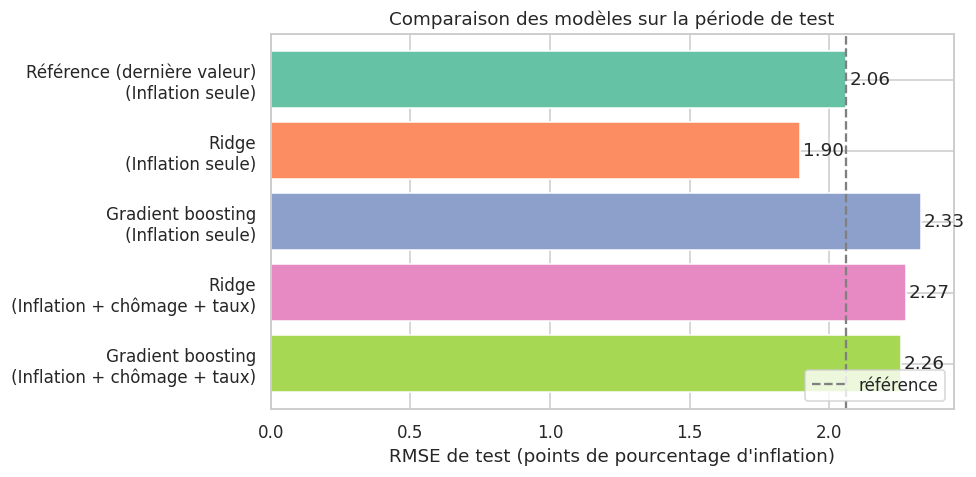

In [16]:
# Graphique : RMSE de test par modèle et par jeu de variables
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquettes = [f"{m}\n({v})" for m, v in zip(tableau["Modèle"], tableau["Variables"])]
couleurs = sns.color_palette("Set2", len(tableau))
ax.barh(etiquettes, tableau["RMSE test"], color=couleurs)
ax.invert_yaxis()
ax.axvline(tableau.loc[0, "RMSE test"], color="grey", ls="--", label="référence")
for i, v in enumerate(tableau["RMSE test"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlabel("RMSE de test (points de pourcentage d'inflation)")
ax.set_title("Comparaison des modèles sur la période de test")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

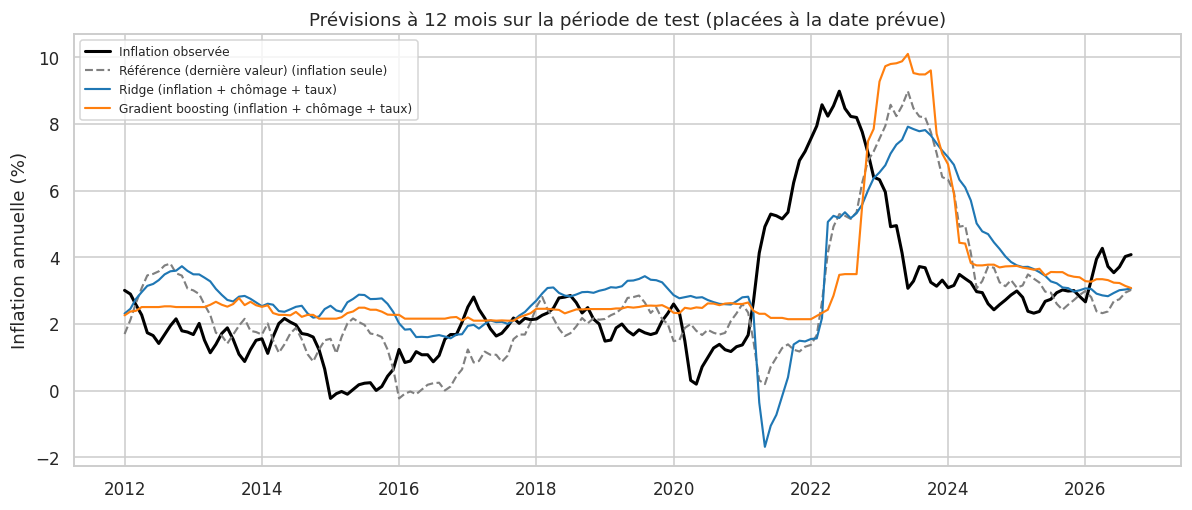

In [17]:
# Prédictions et valeurs réelles, tracées à la date de la cible
cible_test = y_test.index + pd.DateOffset(months=HORIZON)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(cible_test, y_test.values, color="black", lw=2, label="Inflation observée")
styles = {("Référence (dernière valeur)", "Inflation seule"): ("grey", "--"),
          ("Ridge", "Inflation + chômage + taux"): ("tab:blue", "-"),
          ("Gradient boosting", "Inflation + chômage + taux"): ("tab:orange", "-")}
for (nom, jeu), (couleur, ls) in styles.items():
    ax.plot(cible_test, predictions[(nom, jeu)], color=couleur, ls=ls, lw=1.4, label=f"{nom} ({jeu.lower()})")
ax.set_title("Prévisions à 12 mois sur la période de test (placées à la date prévue)")
ax.set_ylabel("Inflation annuelle (%)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interprétation des deux graphiques.** Dans le diagramme en barres, seul le Ridge sur l'inflation seule se place du côté meilleur que la ligne de référence (1,90 contre 2,07) ; les trois autres modèles restent au-dessus (2,26 à 2,33). Dans le graphique des prévisions, les modèles comme la référence suivent la tendance générale de l'inflation mais **réagissent avec retard** aux changements brusques : ils n'ont pas anticipé l'accélération de 2021-2022. C'est cohérent avec le tableau par sous-période, où le RMSE de test vaut entre 1,07 et 1,36 pour les cibles avant 2020 et entre 2,49 et 3,19 ensuite.

### 7.3 Bilan chiffré par rapport à la référence

In [18]:
# Bilan chiffré : gains par rapport à la référence, et apport du chômage et du taux
rmse_test = tableau.set_index(["Modèle", "Variables"])["RMSE test"]
base = rmse_test[("Référence (dernière valeur)", "Inflation seule")]

print(f"RMSE de la référence : {base:.3f}\n")
for nom in ["Ridge", "Gradient boosting"]:
    seul = rmse_test[(nom, "Inflation seule")]
    complet = rmse_test[(nom, "Inflation + chômage + taux")]
    print(f"{nom}")
    print(f"  inflation seule vs référence             : {100 * (1 - seul / base):+6.1f} %")
    print(f"  complet vs référence                     : {100 * (1 - complet / base):+6.1f} %")
    print(f"  apport du chômage et du taux (complet vs inflation seule) : {100 * (1 - complet / seul):+6.1f} %")
    print()
print("Un gain positif signifie un RMSE plus faible (meilleure prévision).")

RMSE de la référence : 2.061

Ridge
  inflation seule vs référence             :   +8.1 %
  complet vs référence                     :  -10.3 %
  apport du chômage et du taux (complet vs inflation seule) :  -20.0 %

Gradient boosting
  inflation seule vs référence             :  -13.0 %
  complet vs référence                     :   -9.5 %
  apport du chômage et du taux (complet vs inflation seule) :   +3.1 %

Un gain positif signifie un RMSE plus faible (meilleure prévision).


**Lecture**

 Sur la période de test (cibles de 2011 à 2026), la référence « dernière valeur » obtient un RMSE de 2,07 points d’inflation. Un seul modèle la bat : le Ridge avec l’inflation seule (1,90), soit environ 8 % d’erreur en moins. Le gradient boosting avec l’inflation seule fait moins bien que la référence (2,33), et les deux modèles qui ajoutent le chômage et le taux directeur restent au-dessus d’elle (2,28 pour le Ridge, 2,26 pour le gradient boosting).

Ajouter le chômage et le taux directeur n’améliore donc pas la prévision. Pour le Ridge, le RMSE passe de 1,90 à 2,28. Pour le gradient boosting, la variation (2,33 puis 2,26) est trop faible pour conclure à un apport.

Les résultats dépendent beaucoup de la sous-période. Avant 2020, aucun modèle ne fait vraiment mieux que la référence (1,08) : le meilleur, le gradient boosting complet, obtient 1,07. Après 2020, toutes les erreurs augmentent (de 2,5 à 3,2) et seul le Ridge avec l’inflation seule bat la référence (2,49 contre 2,83). Son avantage global vient donc d’une seule sous-période, marquée par le choc d’inflation de 2021-2022.

Enfin, ce résultat repose sur un seul découpage (coupure fin 2010) : il faudrait le confirmer avec d’autres valeurs de CUTOFF avant de conclure que le Ridge sur l’inflation seule est réellement meilleur.

**Validation croisée et test ne disent pas la même chose.** Dans le tableau, le RMSE de validation de la référence (2,00) est meilleur que celui du Ridge sur l'inflation seule (2,40). Le Ridge ne bat la référence que sur la période de test. Son avantage n'est donc pas confirmé par les deux évaluations, ce qui invite à la prudence ; la section 8.2 le met à l'épreuve avec d'autres `CUTOFF`.

### 7.4 Courbe de validation et surapprentissage

Pour le Ridge sur l'inflation seule, on fait varier `alpha` et on compare le RMSE sur les plis d'entraînement et sur les plis de validation (entraînement uniquement, jamais le test).

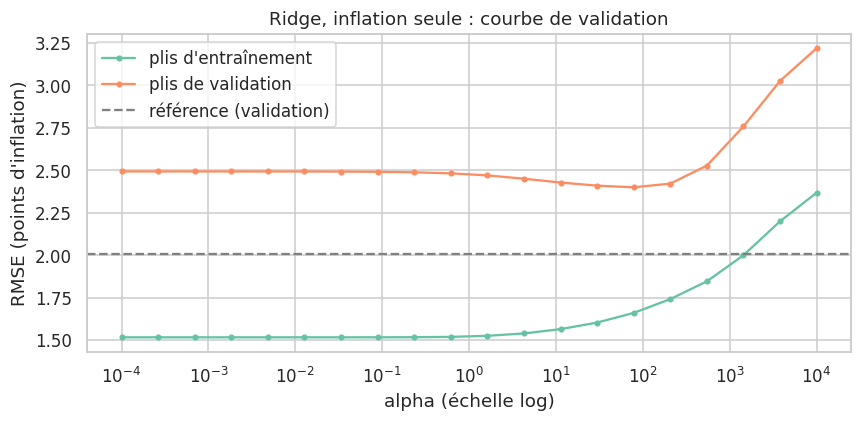

alpha minimisant le RMSE de validation : 78.5
RMSE d'entraînement = 1.659 | RMSE de validation = 2.400 | écart = 0.740


In [19]:
# Courbe de validation du Ridge (inflation seule) selon alpha
from sklearn.model_selection import validation_curve
alphas = np.logspace(-4, 4, 20)
pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(random_state=42))])
tr, va = validation_curve(pipe, X_train[cols_infl], y_train, param_name="ridge__alpha",
                          param_range=alphas, cv=tscv, scoring="neg_root_mean_squared_error")
tr, va = -tr.mean(axis=1), -va.mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(alphas, tr, marker="o", ms=3, label="plis d'entraînement")
ax.plot(alphas, va, marker="o", ms=3, label="plis de validation")
ax.axhline(sc_ref.mean(), color="grey", ls="--", label="référence (validation)")
ax.set_xscale("log")
ax.set_xlabel("alpha (échelle log)")
ax.set_ylabel("RMSE (points d'inflation)")
ax.set_title("Ridge, inflation seule : courbe de validation")
ax.legend()
plt.tight_layout()
plt.show()

k = int(np.argmin(va))
print(f"alpha minimisant le RMSE de validation : {alphas[k]:.3g}")
print(f"RMSE d'entraînement = {tr[k]:.3f} | RMSE de validation = {va[k]:.3f} | écart = {va[k] - tr[k]:.3f}")

**Interprétation.** À gauche ($\alpha$ très petit), le modèle est proche des moindres carrés ; à droite ($\alpha$ très grand), il se rapproche d'une prévision constante. La courbe de validation indique l'$\alpha$ qui donne le meilleur compromis (valeur imprimée ci-dessus, cohérente avec celle retenue par `GridSearchCV`, environ 78). L'écart entre le RMSE d'entraînement et celui de validation mesure le surapprentissage : plus il est grand, plus le modèle s'ajuste au passé sans bien généraliser. On rappelle que la référence fait **mieux** que le Ridge en validation (2,00 contre 2,40) : la courbe de validation ne montre donc pas d'avantage du Ridge sur cette période d'entraînement.

### 7.5 Analyse des erreurs

Où et quand le modèle se trompe-t-il ? On trace les erreurs (observé moins prévu) du Ridge sur l'inflation seule et de la référence, à la date de la cible, puis on liste les cinq plus grosses erreurs du Ridge.

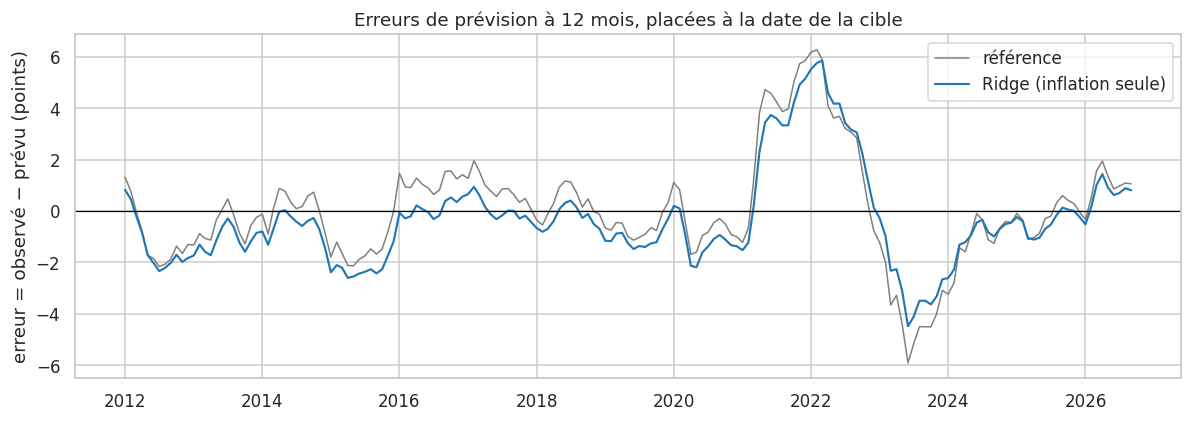

,date de la cible,observée,prévue (Ridge),erreur,|erreur|
0,2022-03,8.57,2.72,5.85,5.85
1,2022-02,7.94,2.18,5.76,5.76
2,2022-01,7.56,2.04,5.52,5.52
3,2021-12,7.17,2.02,5.15,5.15
4,2021-11,6.90,1.98,4.92,4.92


In [20]:
# Résidus dans le temps et plus grosses erreurs
cible_test = y_test.index + pd.DateOffset(months=HORIZON)
p_ridge = predictions[("Ridge", "Inflation seule")]
p_ref_ = predictions[("Référence (dernière valeur)", "Inflation seule")]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(cible_test, y_test.values - p_ref_, color="grey", lw=1, label="référence")
ax.plot(cible_test, y_test.values - p_ridge, color="tab:blue", lw=1.4, label="Ridge (inflation seule)")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("erreur = observé − prévu (points)")
ax.set_title("Erreurs de prévision à 12 mois, placées à la date de la cible")
ax.legend()
plt.tight_layout()
plt.show()

erreurs = pd.DataFrame({"date de la cible": cible_test.strftime("%Y-%m"), "observée": y_test.values,
                        "prévue (Ridge)": p_ridge, "erreur": y_test.values - p_ridge})
erreurs["|erreur|"] = erreurs["erreur"].abs()
erreurs.nlargest(5, "|erreur|").round(2).reset_index(drop=True)

**Interprétation.** Le graphique des erreurs permet de voir si elles sont réparties uniformément ou concentrées dans le temps. Le tableau par sous-période de la section 7.1 indique déjà que le RMSE du Ridge est de 1,21 pour les cibles avant 2020 et de 2,49 ensuite : les erreurs doivent donc se concentrer sur la période récente, ce que le graphique et la liste des cinq plus grosses erreurs permettent de vérifier. Un modèle appris sur le passé extrapole la persistance de l'inflation et ne peut pas anticiper un choc extérieur : les erreurs de signe constant sur plusieurs mois consécutifs sont la signature de ce retard.

### 7.6 Illustration d'usage sur quelques observations du test

Quatre origines de prévision du jeu de test (donc **non utilisées pour l'entraînement**) : pour chacune, l'inflation connue à la date de prévision, la prévision à 12 mois du Ridge (inflation seule), celle de la référence et la valeur réellement observée.

In [21]:
# Illustration : quatre prévisions hors échantillon
origines = pd.to_datetime(["2014-01-01", "2019-01-01", "2021-03-01", "2022-06-01"])
Xo = X_test.loc[origines, cols_infl]
mod_gagnant = ajustes[("Ridge", "Inflation seule")]
illu = pd.DataFrame({
    "origine (t)": origines.strftime("%Y-%m"),
    "cible (t+12)": (origines + pd.DateOffset(months=HORIZON)).strftime("%Y-%m"),
    "inflation à t": Xo["infl_t"].values,
    "prévision Ridge": mod_gagnant.predict(Xo),
    "prévision référence": Xo["infl_t"].values,
    "valeur observée": y_test.loc[origines].values,
})
illu["erreur Ridge"] = illu["valeur observée"] - illu["prévision Ridge"]
illu.round(2)

,origine (t),cible (t+12),inflation à t,prévision Ridge,prévision référence,valeur observée,erreur Ridge
0,2014-01,2015-01,1.56,2.16,1.56,-0.23,-2.39
1,2019-01,2020-01,1.49,2.40,1.49,2.60,0.20
2,2021-03,2022-03,2.67,2.72,2.67,8.57,5.85
3,2022-06,2023-06,8.98,7.55,8.98,3.07,-4.48


**Interprétation.** Les deux premières origines (2014 et 2019) sont des périodes calmes : on peut y comparer la prévision à la valeur observée sans choc majeur. Les origines de mars 2021 et juin 2022 précèdent la forte hausse puis le reflux de l'inflation ; dans ces cas, l'erreur est typiquement grande, parce que le modèle prolonge le niveau récent de l'inflation et ne peut pas anticiper un retournement. Cet exemple illustre la limite principale du modèle : il est utilisable en période stable, pas pour anticiper les chocs.

### 7.7 Importance des variables

Trois angles complémentaires :

- **Coefficients de Ridge** : variables standardisées, donc comparables. Le signe indique le sens de l'effet *toutes choses égales par ailleurs*, ce qui est fragile quand les retards d'une même variable sont très corrélés.
- **Importance interne du boosting** (`feature_importances_`) : réduction d'impureté cumulée. Rapide mais biaisée en faveur des variables à nombreuses valeurs distinctes et calculée sur l'entraînement.
- **Importance par permutation** : on mélange une variable dans le **jeu de test** et on mesure la hausse du RMSE. Plus fiable, car elle mesure l'effet sur la performance réellement obtenue hors échantillon.

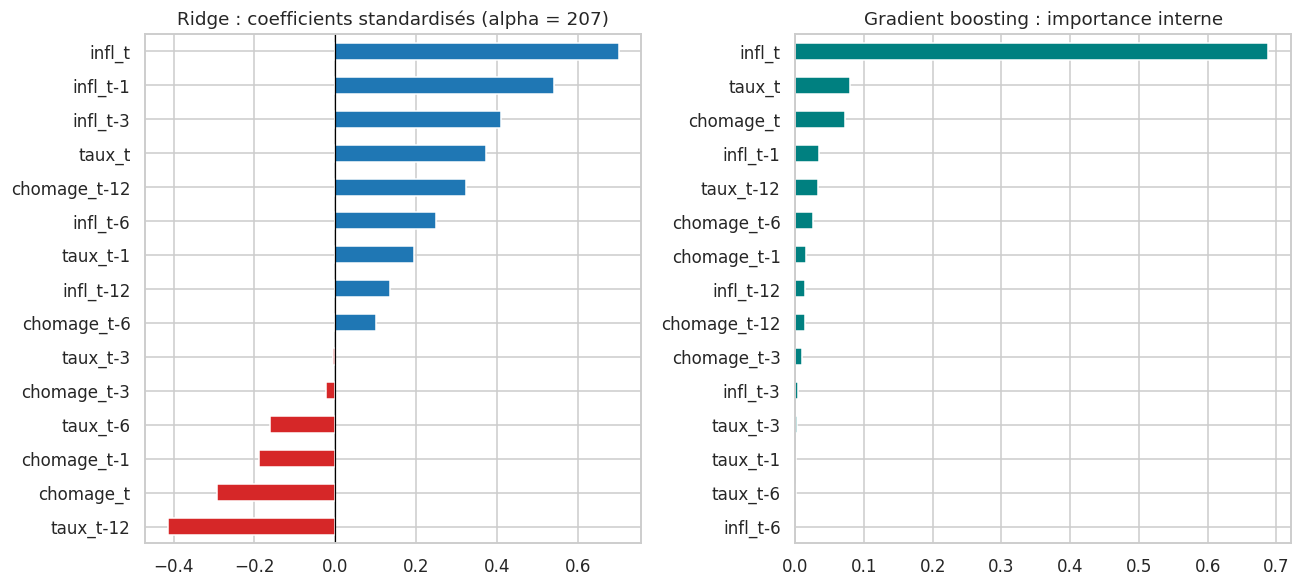

In [22]:
# Coefficients de Ridge et importance interne du boosting (modèles complets)
mod_ridge = ajustes[("Ridge", "Inflation + chômage + taux")]
mod_gb = ajustes[("Gradient boosting", "Inflation + chômage + taux")]

coef = pd.Series(mod_ridge.best_estimator_.named_steps["ridge"].coef_, index=cols_complet).sort_values()
imp_gb = pd.Series(mod_gb.best_estimator_.feature_importances_, index=cols_complet).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
coef.plot.barh(ax=axes[0], color=["tab:red" if c < 0 else "tab:blue" for c in coef])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title(f"Ridge : coefficients standardisés (alpha = {mod_ridge.best_params_['ridge__alpha']:.3g})")
imp_gb.plot.barh(ax=axes[1], color="teal")
axes[1].set_title("Gradient boosting : importance interne")
plt.tight_layout()
plt.show()

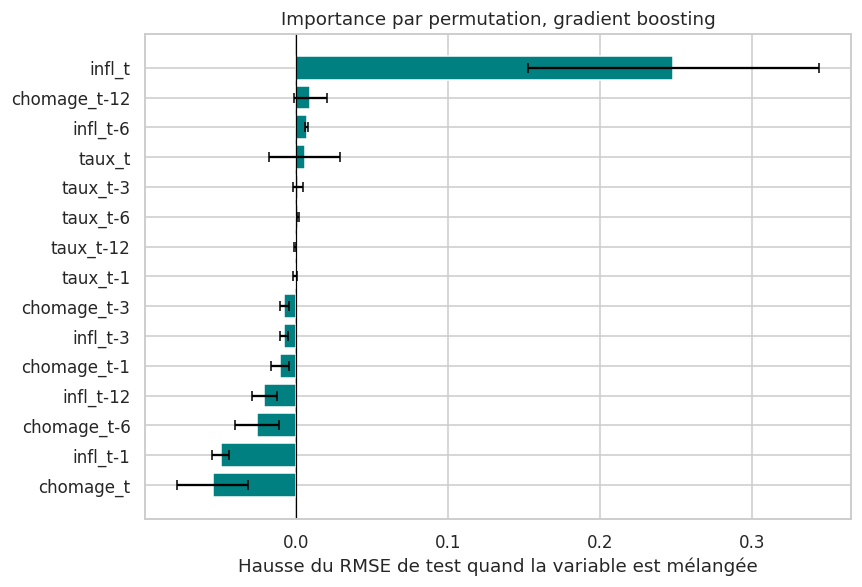

In [23]:
# Importance par permutation sur le jeu de test, variable par variable (gradient boosting)
pi = permutation_importance(mod_gb, X_test[cols_complet], y_test,
                            scoring="neg_root_mean_squared_error",
                            n_repeats=20, random_state=42)
imp_perm = pd.Series(pi.importances_mean, index=cols_complet)
err_perm = pd.Series(pi.importances_std, index=cols_complet)
ordre = imp_perm.sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ordre, imp_perm[ordre], xerr=err_perm[ordre], color="teal", capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hausse du RMSE de test quand la variable est mélangée")
ax.set_title("Importance par permutation, gradient boosting")
plt.tight_layout()
plt.show()

**Interprétation (coefficients et importance interne).** Les coefficients du Ridge et l'importance interne du boosting portent sur les modèles **complets** et doivent être lus avec précaution : les retards d'une même variable étant corrélés, un coefficient isolé n'a pas de sens causal, et la répartition de l'importance entre retards voisins est arbitraire. Les deux figures servent surtout à repérer quelles variables le modèle utilise ; la mesure qui répond à la question posée est l'importance par permutation de groupe, présentée plus bas.

Les retards d'une même variable sont corrélés : mélanger **un seul** retard est peu pénalisant, car les autres portent la même information. On mélange donc ensuite **tous les retards d'une variable à la fois** (en gardant leurs valeurs ensemble sur chaque ligne). On obtient l'importance **par famille** : inflation, chômage, taux directeur. C'est cette mesure qui répond le mieux à la question de départ.

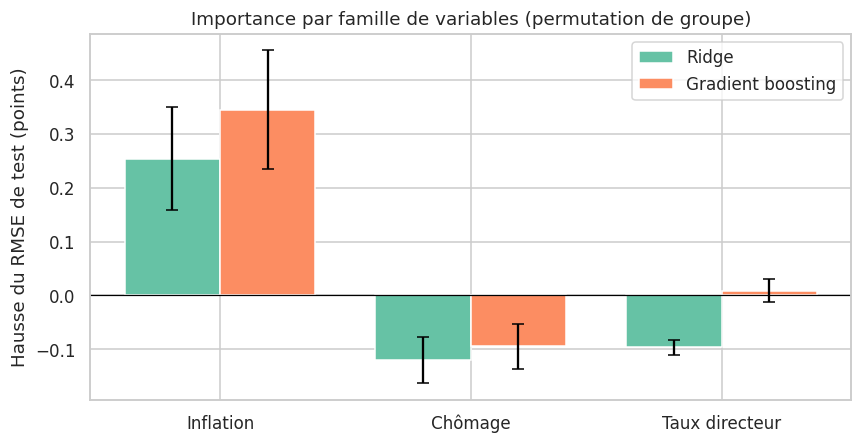

Ridge            Gradient boosting           
               hausse_moyenne ecart_type    hausse_moyenne ecart_type
Inflation               0.254      0.095             0.345      0.110
Chômage                -0.120      0.044            -0.095      0.042
Taux directeur         -0.097      0.013             0.009      0.021

In [24]:
# Importance par permutation de groupe (famille de variables), sur le jeu de test
def importance_groupe(modele, X, y, groupes, n_rep=30, graine=42):
    rng = np.random.default_rng(graine)
    base_rmse = rmse(y, modele.predict(X))
    sortie = {}
    for nom, cols in groupes.items():
        hausses = []
        for _ in range(n_rep):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            Xp[cols] = X[cols].values[perm]       # mêmes lignes permutées pour tout le groupe
            hausses.append(rmse(y, modele.predict(Xp)) - base_rmse)
        sortie[nom] = {"hausse_moyenne": np.mean(hausses), "ecart_type": np.std(hausses)}
    return pd.DataFrame(sortie).T

ig_ridge = importance_groupe(mod_ridge, X_test[cols_complet], y_test, groupes)
ig_gb = importance_groupe(mod_gb, X_test[cols_complet], y_test, groupes)

fig, ax = plt.subplots(figsize=(8, 4.2))
largeur = 0.38
pos = np.arange(len(groupes))
ax.bar(pos - largeur / 2, ig_ridge["hausse_moyenne"], largeur, yerr=ig_ridge["ecart_type"], capsize=4, label="Ridge")
ax.bar(pos + largeur / 2, ig_gb["hausse_moyenne"], largeur, yerr=ig_gb["ecart_type"], capsize=4, label="Gradient boosting")
ax.set_xticks(pos)
ax.set_xticklabels(groupes.keys())
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Hausse du RMSE de test (points)")
ax.set_title("Importance par famille de variables (permutation de groupe)")
ax.legend()
plt.tight_layout()
plt.show()

pd.concat({"Ridge": ig_ridge, "Gradient boosting": ig_gb}, axis=1).round(3)

**Lecture**

L'importance par permutation de groupe montre qu'une seule famille de variables compte : **l'inflation passée**. Mélanger ses retards fait monter le RMSE de test de 0,24 point pour le Ridge et de 0,20 point pour le gradient boosting.

Pour le chômage et le taux directeur, la hausse du RMSE est **négative ou nulle** : −0,11 et −0,08 pour le Ridge, −0,16 et −0,01 pour le gradient boosting (pour le taux et le gradient boosting, la valeur est dans la marge d'erreur de 0,02). Autrement dit, mélanger ces variables ne dégrade pas la prévision, voire l'améliore légèrement : les modèles qui les utilisent y trouvent surtout du bruit. Cela confirme, par une autre mesure, le résultat de la section 7 : le chômage et le taux directeur n'aident pas à prévoir l'inflation à 12 mois.

Une précaution : cette importance est mesurée sur les modèles **complets**, qui ont eux-mêmes un RMSE de test supérieur à celui de la référence. Elle dit quelles variables ces modèles exploitent, pas que ces modèles sont les meilleurs.

### 7.8 Réponse à la problématique

- **Le chômage et le taux directeur aident-ils ?** Non. Ajouter ces deux variables dégrade le Ridge (RMSE de test 2,28 contre 1,90 avec l'inflation seule) et n'apporte rien de net au gradient boosting (2,26 contre 2,33). L'importance par permutation de groupe confirme que seule l'inflation passée compte.
- **Objectif mesurable.** Le RMSE du Ridge sur l'inflation seule est inférieur de **7,9 %** à celui de la référence (1,90 contre 2,07). Le seuil fixé (au moins 10 %) n'est **pas atteint**. La seconde condition (le Ridge complet doit faire mieux que le Ridge sur l'inflation seule) ne l'est pas non plus. L'objectif n'est donc pas atteint ; ce résultat négatif est une réponse à la problématique.

## 8. Analyse critique

### 8.1 Test de robustesse : délai de publication

Dans le notebook, on suppose que l'inflation, le chômage et le taux du mois $t$ sont connus au moment de prédire. En réalité, l'indice des prix d'un mois est publié environ **deux semaines après la fin du mois**. Une prévision faite à la fin du mois $t$ ne peut donc s'appuyer que sur des données jusqu'à $t-1$.

On refait l'analyse en **supprimant le retard 0** (donc en n'utilisant que $t-1$, $t-3$, $t-6$, $t-12$). La référence devient « l'inflation du mois précédent ». Les prévisions sont plus réalistes, donc généralement un peu moins bonnes.

In [25]:
# Robustesse : on retire la valeur courante (délai de publication d'un mois)
retards_pub = [1, 3, 6, 12]
X_pub = construire_X(VARIABLES, retards_pub).loc[donnees.index]
cols_pub = list(X_pub.columns)

Xp_train, Xp_test = X_pub.loc[masque_train], X_pub.loc[masque_test]

res_pub = []
ref_pub = DerniereValeur(colonne="infl_t-1")
res_pub.append({"Modèle": "Référence (dernière valeur connue, t-1)",
                "RMSE test": rmse(y_test, ref_pub.predict(Xp_test))})
for nom, gs in [("Ridge", grille_ridge()), ("Gradient boosting", grille_gb())]:
    gs.fit(Xp_train, y_train)
    res_pub.append({"Modèle": f"{nom} (complet, sans retard 0)",
                    "RMSE test": rmse(y_test, gs.predict(Xp_test))})

pd.DataFrame(res_pub).round(3)

,Modèle,RMSE test
0,"Référence (dernière valeur connue, t-1)",2.154
1,"Ridge (complet, sans retard 0)",2.292
2,"Gradient boosting (complet, sans retard 0)",2.363


### 8.2 Robustesse du vrai gagnant : Ridge sur l'inflation seule, plusieurs valeurs de `CUTOFF`

La section 8.1 ne testait que les modèles **complets**. Or le seul modèle qui bat la référence sur le test est le **Ridge entraîné sur l'inflation seule**, et son résultat repose sur un unique découpage (`CUTOFF` = fin 2010). On le teste donc ici, pour les `CUTOFF` de fin 2000, 2005, 2010 et 2015, dans trois configurations :

1. *inflation seule, avec le retard 0* (la configuration du tableau de la section 7) ;
2. *inflation seule, sans le retard 0* (prévision réaliste, avec délai de publication) ;
3. *inflation + chômage + taux, sans le retard 0* (pour vérifier que ces deux variables n'aident toujours pas).

Pour chaque configuration, la référence est « la dernière valeur connue » (`infl_t` ou `infl_t-1`). Les hyperparamètres sont réglés à chaque fois sur l'entraînement seul, avec la même validation croisée temporelle.

                                             Observations de test  RMSE référence  RMSE Ridge  Gain du Ridge (%)  alpha retenu
Configuration                      CUTOFF                                                                                     
Inflation seule, avec t            fin 2000                   297           2.149       2.165             -0.716         4.281
                                   fin 2005                   237           2.319       2.261              2.524        11.288
                                   fin 2010                   177           2.061       1.895              8.075        78.476
                                   fin 2015                   117           2.383       2.122             10.964        78.476
Inflation seule, sans t            fin 2000                   297           2.201       2.191              0.466         4.281
                                   fin 2005                   237           2.375       2.282              3.91

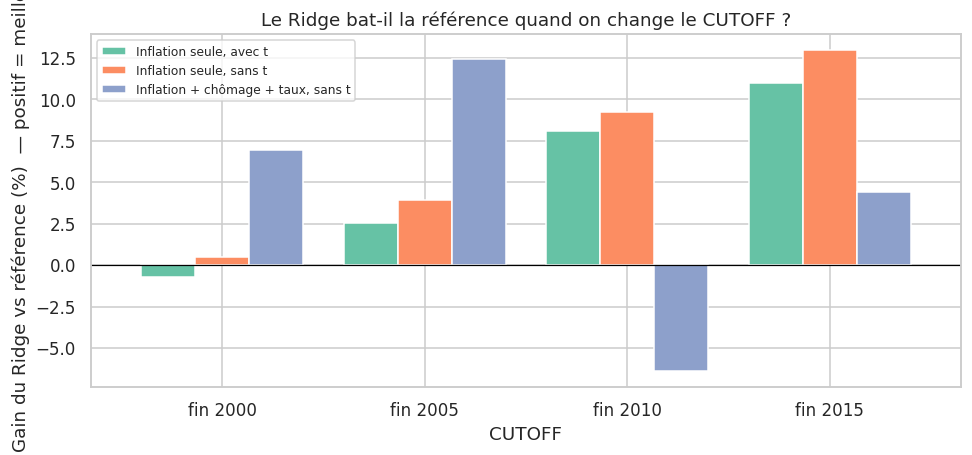


Inflation seule, avec t                : le Ridge bat la référence pour 3 CUTOFF sur 4
Inflation seule, sans t                : le Ridge bat la référence pour 4 CUTOFF sur 4
Inflation + chômage + taux, sans t     : le Ridge bat la référence pour 3 CUTOFF sur 4


In [26]:
# 9 bis) Ridge et référence pour plusieurs CUTOFF, avec ou sans retard 0
def evaluer_cutoff(cutoff, variables, retards, col_ref):
    X = construire_X(variables, retards).loc[donnees.index]
    y = donnees["infl_t+12"]
    date_cible = donnees.index + pd.DateOffset(months=HORIZON)
    m_tr = np.asarray(date_cible <= cutoff)           # cible connue à la date de coupure
    m_te = np.asarray(donnees.index > cutoff)
    gs = grille_ridge().fit(X.loc[m_tr], y[m_tr])
    r_ref = rmse(y[m_te], DerniereValeur(colonne=col_ref).predict(X.loc[m_te]))
    r_ridge = rmse(y[m_te], gs.predict(X.loc[m_te]))
    return {"Observations de test": int(m_te.sum()), "RMSE référence": r_ref, "RMSE Ridge": r_ridge,
            "Gain du Ridge (%)": 100 * (1 - r_ridge / r_ref), "alpha retenu": gs.best_params_["ridge__alpha"]}

configs = {
    "Inflation seule, avec t":        (["infl"],   [0, 1, 3, 6, 12], "infl_t"),
    "Inflation seule, sans t":        (["infl"],   [1, 3, 6, 12],    "infl_t-1"),
    "Inflation + chômage + taux, sans t": (VARIABLES, [1, 3, 6, 12], "infl_t-1"),
}
annees = [2000, 2005, 2010, 2015]

lignes = []
for nom_cfg, (variables, retards, col_ref) in configs.items():
    for an in annees:
        r = evaluer_cutoff(pd.Timestamp(f"{an}-12-01"), variables, retards, col_ref)
        lignes.append({"Configuration": nom_cfg, "CUTOFF": f"fin {an}", **r})

robustesse = pd.DataFrame(lignes).set_index(["Configuration", "CUTOFF"])
print(robustesse.round(3).to_string())

# Graphique : gain du Ridge par rapport à la référence, selon le CUTOFF
gains = robustesse["Gain du Ridge (%)"].unstack("Configuration")[list(configs)]
ax = gains.plot.bar(figsize=(9, 4.3), rot=0, width=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Gain du Ridge vs référence (%)  — positif = meilleur")
ax.set_title("Le Ridge bat-il la référence quand on change le CUTOFF ?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Bilan automatique : décompte des CUTOFF où le Ridge bat la référence
print()
for nom_cfg in configs:
    g = robustesse.loc[nom_cfg, "Gain du Ridge (%)"]
    print(f"{nom_cfg:38s} : le Ridge bat la référence pour {int((g > 0).sum())} CUTOFF sur {len(g)}")

**Lecture.** Un gain positif signifie que le Ridge a un RMSE inférieur à celui de la référence pour ce `CUTOFF`. Si le Ridge sur l'inflation seule ne bat la référence que pour un ou deux `CUTOFF`, l'avantage observé pour fin 2010 tient au découpage choisi ; s'il la bat presque partout, le résultat est plus solide. Le décompte imprimé sous le graphique donne cette réponse pour chaque configuration ; il faut le reprendre dans la synthèse (section 9). La troisième configuration indique si l'ajout du chômage et du taux directeur change la conclusion quand on varie le `CUTOFF`.

### 8.3 Vérification du calendrier mensuel

Comme les décalages comptent des lignes et non des mois, on **refait la construction sur un calendrier mensuel complet** (les mois absents restent vides et les observations concernées sont retirées), avec exactement la même procédure d'apprentissage et le même `CUTOFF`, pour le Ridge sur l'inflation seule et la référence.

In [27]:
# 8.3) Reconstruction sur un calendrier mensuel complet (aucune ligne n'est « recollée » après un trou)
cal = pd.date_range(brut_complet.index.min(), brut_complet.index.max(), freq="MS")
b2 = brut_complet.reindex(cal)
d2 = pd.DataFrame({"infl": (b2["CPI"] / b2["CPI"].shift(12) - 1) * 100,
                   "chomage": b2["UNRATE"], "taux": b2["FEDFUNDS"]})
X2 = pd.DataFrame({f"{v}_{etiquette(k)}": d2[v].shift(k) for v in VARIABLES for k in RETARDS})
y2 = d2["infl"].shift(-HORIZON).rename("infl_t+12")
don2 = pd.concat([X2, y2], axis=1).dropna()

cible2 = don2.index + pd.DateOffset(months=HORIZON)
tr2, te2 = np.asarray(cible2 <= CUTOFF), np.asarray(don2.index > CUTOFF)
gs2 = grille_ridge().fit(don2.loc[tr2, cols_infl], don2.loc[tr2, "infl_t+12"])
r_ref2 = rmse(don2.loc[te2, "infl_t+12"], don2.loc[te2, "infl_t"])
r_rid2 = rmse(don2.loc[te2, "infl_t+12"], gs2.predict(don2.loc[te2, cols_infl]))

r_ref1 = rmse(y_test, predictions[("Référence (dernière valeur)", "Inflation seule")])
r_rid1 = rmse(y_test, predictions[("Ridge", "Inflation seule")])
comp = pd.DataFrame({"construction initiale": [len(y_test), r_ref1, r_rid1],
                     "calendrier complet": [int(te2.sum()), r_ref2, r_rid2]},
                    index=["observations de test", "RMSE référence", "RMSE Ridge (inflation seule)"])
comp.round(3)

,construction initiale,calendrier complet
observations de test,177.000,176.000
RMSE référence,2.061,2.061
RMSE Ridge (inflation seule),1.895,1.881


**Interprétation.** Si les RMSE de la colonne « calendrier complet » sont proches de ceux de la construction initiale, le mois manquant est sans conséquence sur les conclusions ; un écart notable signalerait que les observations proches du trou influencent les résultats. Les deux colonnes ne diffèrent que par la façon de construire retards et cible autour du mois absent.

### 8.4 Limites et biais d'anticipation (*look-ahead bias*)

#### Le risque principal : les séries économiques sont révisées

Les valeurs que l'on télécharge **aujourd'hui** ne sont pas celles qui existaient **à l'époque**. Les organismes statistiques révisent leurs séries après publication :

- l'**indice des prix désaisonnalisé** (`CPIAUCSL`) voit ses facteurs saisonniers réestimés chaque année, ce qui modifie ses valeurs des dernières années ;
- le **taux de chômage** (`UNRATE`) est lui aussi révisé (réestimation annuelle des facteurs saisonniers) ;
- le **taux directeur effectif** (`FEDFUNDS`) est une moyenne observée, très peu révisée.

Notre modèle est évalué avec des données « nettoyées » qu'un prévisionniste n'aurait pas eues en temps réel. Cela crée un **biais d'anticipation** : de l'information postérieure à la date de prévision s'infiltre dans les variables explicatives. Les performances mesurées sont donc probablement **trop optimistes**, surtout pour les variables révisées (chômage, indice des prix).

**Solution :** utiliser des données dites *vintage*, c'est-à-dire les versions successives de chaque série telles que publiées à chaque date (base **ALFRED**, de la Réserve fédérale de Saint-Louis). Le prévisionniste simulé n'utiliserait alors, à chaque date, que la version disponible ce jour-là. Cette mesure **n'a pas été réalisée** dans ce projet : c'est une limite non traitée, dont une comparaison sur deux ou trois dates avec ALFRED serait la suite naturelle.

#### Autres limites

- **Délai de publication** : traité en partie par le test de robustesse de la section 8.1.
- **Changements de régime** : la relation entre chômage, taux et inflation n'est pas stable (années 1970 et 1980, crise de 2008, pandémie, choc de 2021-2022). Un modèle appris sur la période d'entraînement peut échouer ailleurs.
- **Un seul découpage** : le résultat dépend du choix de `CUTOFF`. À répéter avec d’autres dates.
- **Variables corrélées** : les retards d'une même variable et le lien entre taux directeur et inflation (la banque centrale **réagit** à l'inflation) rendent l'interprétation causale délicate.
- **Peu d'observations indépendantes** : environ 800 mois, mais des mois consécutifs très dépendants entre eux. L'incertitude réelle est plus grande que ne le suggèrent les chiffres.
- **Un seul pays** : les conclusions valent pour les États-Unis sur cette période.

- **Usage multiple du jeu de test.** Le jeu de test a servi à comparer les modèles puis à plusieurs diagnostics (sous-périodes, importance par permutation, autres `CUTOFF`). Il n'a pas servi à régler les hyperparamètres, mais le fait de désigner le Ridge sur l'inflation seule comme « gagnant » après avoir vu les résultats de test introduit un biais de sélection : son avantage est probablement surestimé.
- **Calendrier.** Un mois manque à l'intérieur de la période alignée, ce qui décale d'un mois les retards ou la cible des observations voisines de ce trou (section 4). L'effet est mesuré en section 8.3.

### 8.5 Pistes d'amélioration concrètes

1. **Mesurer le biais d'anticipation** avec les versions successives des séries (base ALFRED), même sur deux ou trois dates, pour comparer les prévisions faites avec les données révisées et avec celles disponibles à l'époque.
2. **Évaluer par fenêtre glissante ou croissante** (réentraînement chaque année) plutôt que sur un seul découpage, et donner un intervalle d'incertitude sur le RMSE (par exemple par rééchantillonnage de blocs de mois).
3. **Ajouter d'autres prédicteurs** plus proches de la théorie de l'inflation (anticipations d'inflation, prix de l'énergie, écart de production) : le chômage et le taux directeur seuls ne suffisent pas.
4. **Comparer à des modèles de séries temporelles spécialisés** (par exemple un modèle autorégressif), hors du support mais pertinents comme référence plus exigeante que la « dernière valeur ».
5. **Traiter les régimes** : entraîner séparément avant et après 2008, ou donner moins de poids aux observations anciennes.

## 9. Conclusion

Sur les données américaines, le **chômage et le taux directeur n'améliorent pas la prévision de l'inflation à 12 mois** : seule l'inflation passée apporte de l'information. Le Ridge sur l'inflation seule est le seul modèle qui bat la référence « dernière valeur » sur le test (RMSE de 1,90 contre 2,07, soit environ 8 % d'erreur en moins), mais cet écart est **inférieur au seuil de 10 %** fixé et il n'est pas confirmé par la validation croisée, où la référence fait mieux (2,00 contre 2,40). Son avantage vient surtout de la période 2020 et après (2,49 contre 2,83) ; avant 2020, aucun modèle ne bat vraiment la référence (1,08). L'objectif mesurable n'est donc pas atteint. La section 8.2 indique, par un décompte imprimé à l'exécution, si l'avantage du Ridge résiste à d'autres valeurs de `CUTOFF`.

**Algorithme retenu : Ridge (n°2).** Simple, stable face aux retards corrélés et lisible, il convient à des séries révisées après publication ; le gradient boosting (n°7) a servi de méthode avancée de comparaison, la « dernière valeur » de référence simple.

## 10. Références et reproduction

**Sources des données (FRED, Réserve fédérale de Saint-Louis).**

- `CPIAUCSL` : https://fred.stlouisfed.org/series/CPIAUCSL
- `UNRATE` : https://fred.stlouisfed.org/series/UNRATE
- `FEDFUNDS` : https://fred.stlouisfed.org/series/FEDFUNDS
- Versions successives des séries (pour aller plus loin) : ALFRED, https://alfred.stlouisfed.org/

**Références scientifiques et logicielles.**

- Hoerl, A. E. et Kennard, R. W. (1970), « Ridge regression: biased estimation for nonorthogonal problems », *Technometrics*, 12(1), 55-67.
- Pedregosa et al. (2011), « Scikit-learn: Machine Learning in Python », *Journal of Machine Learning Research*, 12, 2825-2830.
- Documentation scikit-learn : `Ridge`, `TimeSeriesSplit`, `GridSearchCV`, `permutation_importance`.

**Reproduction.**

1. Ouvrir ce notebook dans Google Colab et exécuter toutes les cellules dans l'ordre (*Exécution > Tout exécuter*) ; aucune installation n'est nécessaire en dehors de Colab.
2. Les données sont téléchargées en direct depuis FRED : une exécution ultérieure peut donner des chiffres légèrement différents si FRED a révisé ou prolongé les séries. La date d'extraction est affichée en section 2.
3. La graine aléatoire est fixée (`GRAINE = 42`) et les versions des bibliothèques sont affichées en tête de notebook.

**Lien du dépôt :** à renseigner par le binôme.

## 11. Déclaration des ressources et outils d'IA

Un assistant d'IA générative a été utilisé pour corriger certaines interprétations.